# Tugas praktkum : HDBSCAN data kafe

In [1]:
# Memuat fitur numerik data kafe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
df = pd.read_csv('../../dataset_pbl/cafes.csv')
features = ['latitude', 'longitude', 'rating', 'review_count', 'price_min', 'price_max']
X = df[features].fillna(df[features].mean())
X_scaled = StandardScaler().fit_transform(X)
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]

In [2]:
# HDBSCAN dan ringkasan hasil
clusterer = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(X_scaled)
print('Jumlah klaster:', len(set(labels)) - (1 if -1 in labels else 0))
print('Jumlah noise:', list(labels).count(-1))

Jumlah klaster: 4
Jumlah noise: 91


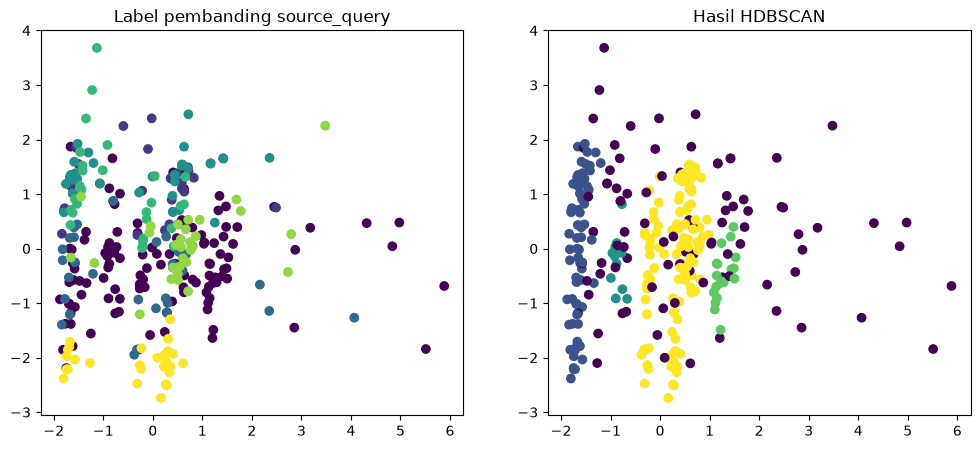

In [3]:
# PCA hanya untuk visualisasi seperti contoh tugas
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_true)
axes[0].set_title('Label pembanding source_query')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
axes[1].set_title('Hasil HDBSCAN')
plt.show()

## Analisis

HDBSCAN membentuk 4 klaster dan menandai 91 baris sebagai noise. Label pembanding source_query memiliki 7 kelompok. Pengelompokan ini tidak dapat dinyatakan cocok dengan kelas sebenarnya karena source_query merupakan kata pencarian saat pengumpulan data, bukan ground truth klaster.